## EDA Project Goal

The goal of the Exploratory Data Analysis (EDA) is to understand the transaction data, assess its quality, identify patterns associated with fraudulent transactions, and uncover insights that support feature engineering, model development, and business decision-making.

## Business Goal of the EDA

The business goal is to discover transaction behaviors and fraud patterns that help financial institutions improve fraud detection strategies, reduce financial losses, strengthen security measures, and enhance customer trust.

## Expected Outcome of the EDA

By completing the EDA, we expect to:

** Understand the structure and quality of the transaction dataset.

** Identify the key characteristics of fraudulent transactions.

** Discover relationships between transaction features and fraud.

** Validate and create meaningful features for the machine learning model.

** Provide actionable recommendations that improve both the fraud detection system and business operations.

In [1]:
import sys

print(sys.executable)

c:\Users\cyril\airflow_tourism_pipeline\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


## Loading Data

In [3]:
df_credit = pd.read_csv(
    r"C:\Users\cyril\airflow_tourism_pipeline\data\cleaned_tourism_data.csv"
)

## Understand the dataset

In [4]:
df_credit.head()

,transaction_date_and_time,transaction_amount,cardholder_name,card_number_(hashed_or_encrypted),merchant_name,merchant_category_code_(mcc),transaction_location_(city_or_zip_code),transaction_currency,card_type,card_expiration_date,cvv_code_(hashed_or_encrypted),transaction_response_code,transaction_id,fraud_flag_or_label,previous_transactions,transaction_source,ip_address,device_information,user_account_information,transaction_notes
0,2020-01-14 21:03:12,3341.97,Lagan Dutt,15bbdcdc198266c9c17633ffb7bf59ef1d48ad76db2267...,Ramesh Inc,9661,Farrukhabad,USD,American Express,05/27,33512007840ced1bb0aab68f47cb5f702abd494a15f26b...,5,92a7490d-89cc-43db-81a9-d152895813aa,1,2,In-Person,112.90.206.208,Mobile,hrishita37,Voluptatem voluptatem officiis alias eius beat...
1,2022-05-08 10:49:06,1117.52,Samiha Ravi,b4f56d425e0ce79c2c27153c2daf9de1a73b1d3be5b6e7...,"Bhasin, Jain and Chada",5678,Dehri,EUR,Visa,09/26,084917af148384c1e8396addcec2fca2a9f2c3918cad96...,12,5849755c-2f70-4f9c-95cc-0092d79d43eb,0,2,Online,150.7.29.164,Mobile,aarna85,Qui quo velit officia tenetur nemo. Quisquam h...
2,2022-08-19 23:40:26,388.16,Vihaan Walla,bd9821d2d86a049aad49919da593e15344bc7604442d9e...,Sha Inc,5772,Gangtok,EUR,Visa,12/25,6165d33e490f91dbf808b194904d4f07c550d5e3a19c9e...,12,7f971cb1-6bd3-48f2-8fa5-2bef220ab4a4,0,1,In-Person,219.61.43.198,Desktop,fatehgupta,Distinctio ex expedita perspiciatis dicta dolo...
3,2022-09-10 05:59:18,4514.53,Ivan Loyal,8d7967ba4a7d372708eca312d518026dd2d83d42e5f0be...,"Sant, Chawla and Wali",8521,Aizawl,USD,Visa,08/29,e6f095e985e6762f1538b47ff1abda58dbe8ce088b16d8...,0,df575129-3416-4c59-b282-d57267515ce1,1,3 or more,In-Person,39.33.247.78,Tablet,ydey,Architecto natus neque fuga. Voluptate dolor i...
4,2020-04-19 15:18:20,1805.22,Hiran Subramaniam,e16012949dcef56d7d31f282999f3e62cb56b4db619d75...,Roy-Dugar,2861,Darbhanga,EUR,American Express,10/28,bb9b8ef813475d1e0ad84e2505af6656d16c990b1f77ef...,12,bd108738-9fe4-46da-9209-065a0bacd9ac,1,2,In-Person,78.90.166.61,Mobile,pseth,Magni harum aliquid quia. Ipsum illo dolores r...


In [6]:
df_credit.shape

(2929, 20)

In [8]:
df_credit.info()

<class 'pandas.DataFrame'>
RangeIndex: 2929 entries, 0 to 2928
Data columns (total 20 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   transaction_date_and_time                2929 non-null   str    
 1   transaction_amount                       2929 non-null   float64
 2   cardholder_name                          2929 non-null   str    
 3   card_number_(hashed_or_encrypted)        2929 non-null   str    
 4   merchant_name                            2929 non-null   str    
 5   merchant_category_code_(mcc)             2929 non-null   int64  
 6   transaction_location_(city_or_zip_code)  2929 non-null   str    
 7   transaction_currency                     2929 non-null   str    
 8   card_type                                2929 non-null   str    
 9   card_expiration_date                     2929 non-null   str    
 10  cvv_code_(hashed_or_encrypted)           2929 non-null   st

In [10]:
df_credit.describe()

,transaction_amount,merchant_category_code_(mcc),transaction_response_code,fraud_flag_or_label
count,2929.000000,2929.000000,2929.000000,2929.000000
mean,2440.061751,5522.203824,5.603960,0.510755
std,1433.030897,2586.037896,4.876711,0.499970
min,1.090000,1004.000000,0.000000,0.000000
25%,1218.040000,3308.000000,0.000000,0.000000
50%,2407.100000,5460.000000,5.000000,1.000000
75%,3687.610000,7761.000000,12.000000,1.000000
max,4996.630000,9994.000000,12.000000,1.000000


## Data Quality Assessment

**Business Question

    Can the data be trusted?

In [15]:
# Missing data values 
missing_values = df_credit.isna().sum()
print("Missing data values:\n" ,missing_values)

Missing data values:
 transaction_date_and_time                  0
transaction_amount                         0
cardholder_name                            0
card_number_(hashed_or_encrypted)          0
merchant_name                              0
merchant_category_code_(mcc)               0
transaction_location_(city_or_zip_code)    0
transaction_currency                       0
card_type                                  0
card_expiration_date                       0
cvv_code_(hashed_or_encrypted)             0
transaction_response_code                  0
transaction_id                             0
fraud_flag_or_label                        0
previous_transactions                      0
transaction_source                         0
ip_address                                 0
device_information                         0
user_account_information                   0
transaction_notes                          0
dtype: int64


In [16]:
# duplicated data
duplicate_data = df_credit.duplicated().sum()
print("Sum of duplicated data\n", duplicate_data)

Sum of duplicated data
 0


## Fraud Distribution

** Business Question:

    How many transactions are fraudulent?

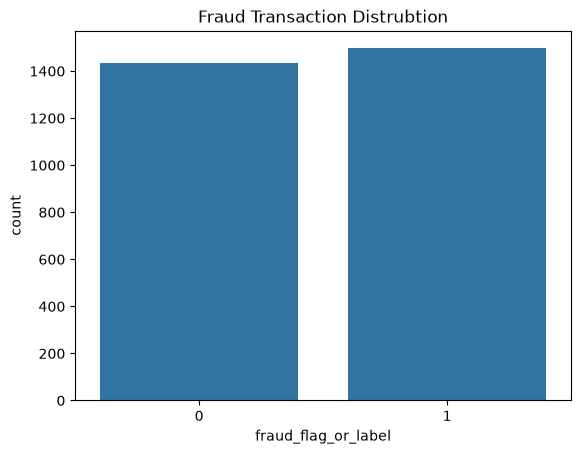

In [17]:
sns.countplot(data=df_credit, x = df_credit.fraud_flag_or_label)
plt.title("Fraud Transaction Distrubtion")
plt.show()

## Transaction Amount Analysis

** Business Question:

    Are fraudulent transactions usually higher value?

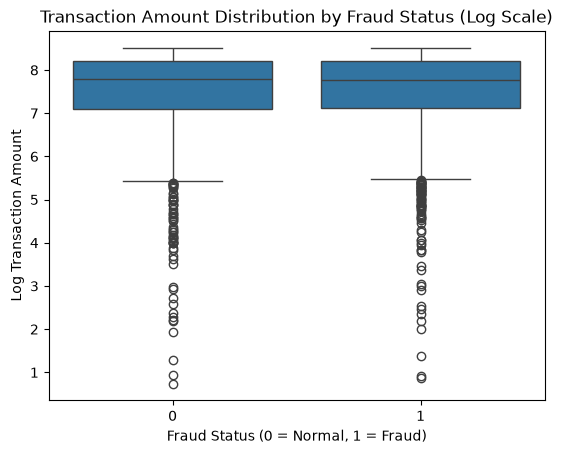

In [19]:
df_credit["log_transaction_amount"] = np.log1p(
    df_credit["transaction_amount"])


sns.boxplot(data=df_credit, x="fraud_flag_or_label", y="log_transaction_amount")


plt.title("Transaction Amount Distribution by Fraud Status (Log Scale)")

plt.xlabel("Fraud Status (0 = Normal, 1 = Fraud)")

plt.ylabel("Log Transaction Amount")

plt.show()

In [20]:
df_credit.groupby( "fraud_flag_or_label")["transaction_amount"].agg(
    ["count",
        "mean",
        "median",
        "max"
    ]
)

,count,mean,median,max
fraud_flag_or_label,,,,
0,1433,2431.639672,2436.390,4996.63
1,1496,2448.129158,2362.235,4993.25


## Fraud by Transaction Source

** Business Question:

    Which channel has more fraud?

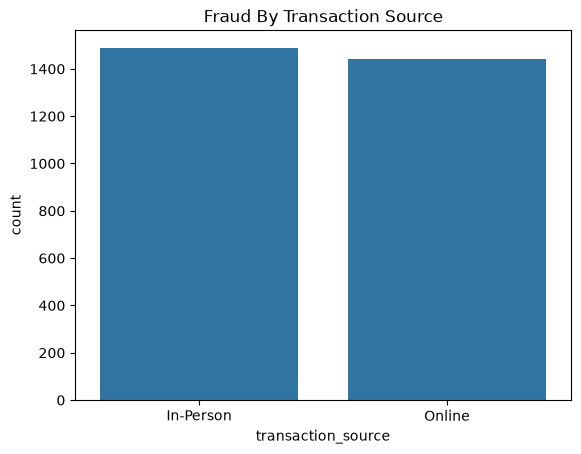

In [21]:
sns.countplot(data= df_credit, x= df_credit.transaction_source)
plt.title("Fraud By Transaction Source")
plt.show()

## Fraud by Device

** Business Question:

    Are certain devices riskier?

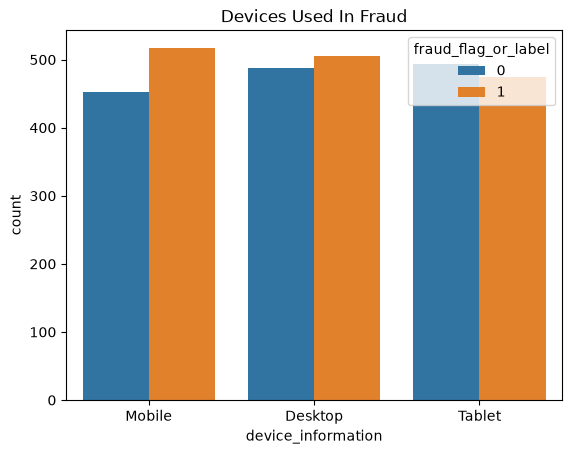

In [22]:
sns.countplot(data=df_credit, x=df_credit.device_information, hue=df_credit.fraud_flag_or_label)
plt.title("Devices Used In Fraud")
plt.show()

## Fraud by Currency

** Business use:

    Identify high-risk regions/currencies.

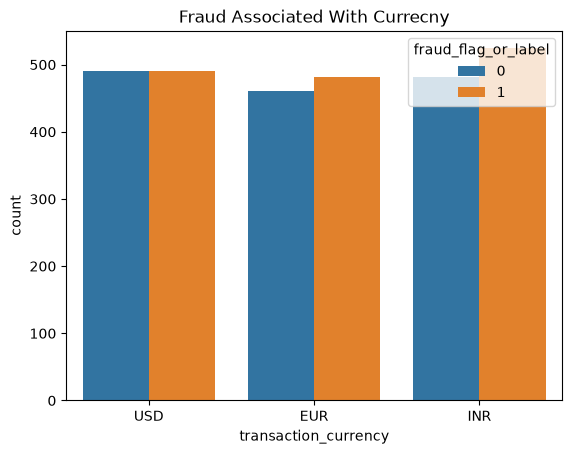

In [24]:
sns.countplot(data=df_credit, x=df_credit.transaction_currency, hue=df_credit.fraud_flag_or_label)
plt.title("Fraud Associated With Currecny")
plt.show()

## Correlation Analysis



** Find relationships between:



    transaction amount

    response code

    fraud label

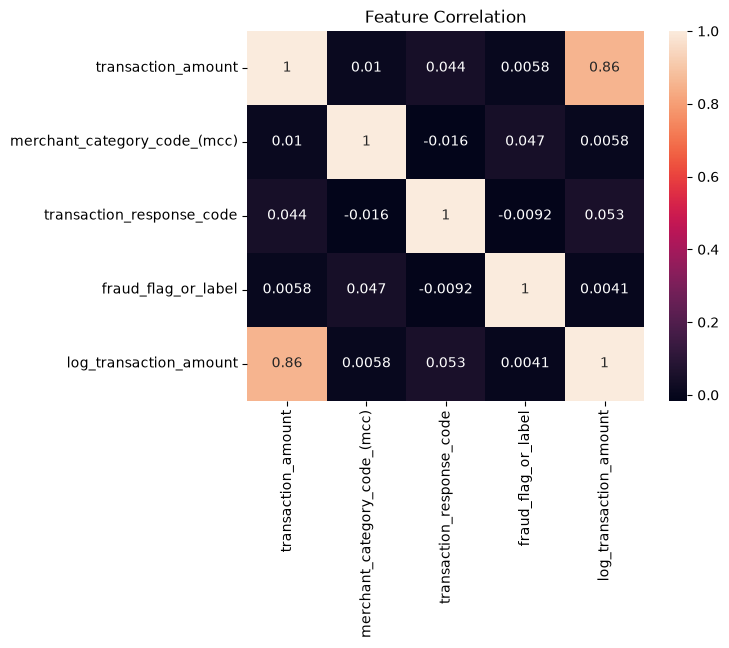

In [25]:
numeric_df = df_credit.select_dtypes(include=np.number)


sns.heatmap(numeric_df.corr(),annot=True)

plt.title("Feature Correlation")

plt.show()

In [29]:
import os

# Create plots folder if it does not exist
os.makedirs(
    "plots",
    exist_ok=True
)

plt.savefig(
    "plots/fraud_distribution.png"
)

<Figure size 640x480 with 0 Axes>

In [31]:
import os
import matplotlib.pyplot as plt

# Create plots folder
os.makedirs("plots", exist_ok=True)

# Save all currently open figures
for i, figure in enumerate(map(plt.figure, plt.get_fignums()), start=1):
    figure.savefig(
        f"plots/eda_plot_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("All plots saved successfully!")

All plots saved successfully!
